# Comparing concentration across public industry portfolios

This native Julia companion preserves the finite examples, public data boundary, concentration measures and absolute tolerance. As the original notebook states, stochastic witnesses and permutation decompositions are nonunique: validation checks mapping, reconstruction, positive mixture weights and total mass. It does not require particular witness entries or permutation lists. All calculations run natively in Julia. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

## A Fixed Public Design Sample

For industry $i$, let $s_i$ be the sample standard deviation of its daily percentage returns in the fixed design period. Two descriptive allocation rules are

$$
w_i^{\mathrm{IVol}}=\frac{s_i^{-1}}{\sum_{j=1}^{n}s_j^{-1}},
\qquad
w_i^{\mathrm{IVar}}=\frac{s_i^{-2}}{\sum_{j=1}^{n}s_j^{-2}}.
$$

Here, $n=16$ is the number of retained public industry portfolios, $w_i^{\mathrm{IVol}}$ is the inverse volatility weight, and $w_i^{\mathrm{IVar}}$ is the inverse variance weight. Both use only observations through 2023. They are descriptive examples of concentration and are not claims about investment performance.

4,Return type,Value-weighted daily percentage returns
5,Industries retained,16
6,Download during execution,None
7,Simulated observations,None


Row,Sample,First date,Last date,Daily observations,Use
,String,Date,Date,Int64,String
1,Design,2019-01-02,2023-12-29,1258,Estimate descriptive weights
2,Later observations,2024-01-02,2025-12-31,502,Count and provenance only
3,Complete fixed window,2019-01-02,2025-12-31,1760,Public data boundary


Row,Industry,Mean daily return (%),Daily volatility (%),Smallest daily return (%),Largest daily return (%)
,String,Float64,Float64,Float64,Float64
1,Agric,0.0727901,1.91047,-14.49,10.73
2,Food,0.0368124,1.09994,-8.74,9.07
3,Soda,0.0479491,1.30502,-9.27,6.54
4,Beer,0.0484261,1.28888,-11.28,11.46
5,Smoke,0.0462321,1.46814,-9.72,10.03
6,Toys,0.0312321,2.39587,-15.81,14.15
7,Fun,0.0512401,2.08027,-15.29,9.77
8,Books,0.0563831,1.67411,-12.72,8.52
9,Hshld,0.0445469,1.22639,-8.82,10.28


Row,Industry,Equal weight (%),Inverse volatility weight (%),Inverse variance weight (%)
,String,Float64,Float64,Float64
1,Agric,6.25,5.11284,3.96946
2,Food,6.25,8.88046,11.9751
3,Soda,6.25,7.48488,8.507
4,Beer,6.25,7.57861,8.7214
5,Smoke,6.25,6.65329,6.72172
6,Toys,6.25,4.07699,2.52399
7,Fun,6.25,4.69552,3.34792
8,Books,6.25,5.83472,5.16949
9,Hshld,6.25,7.96478,9.63285


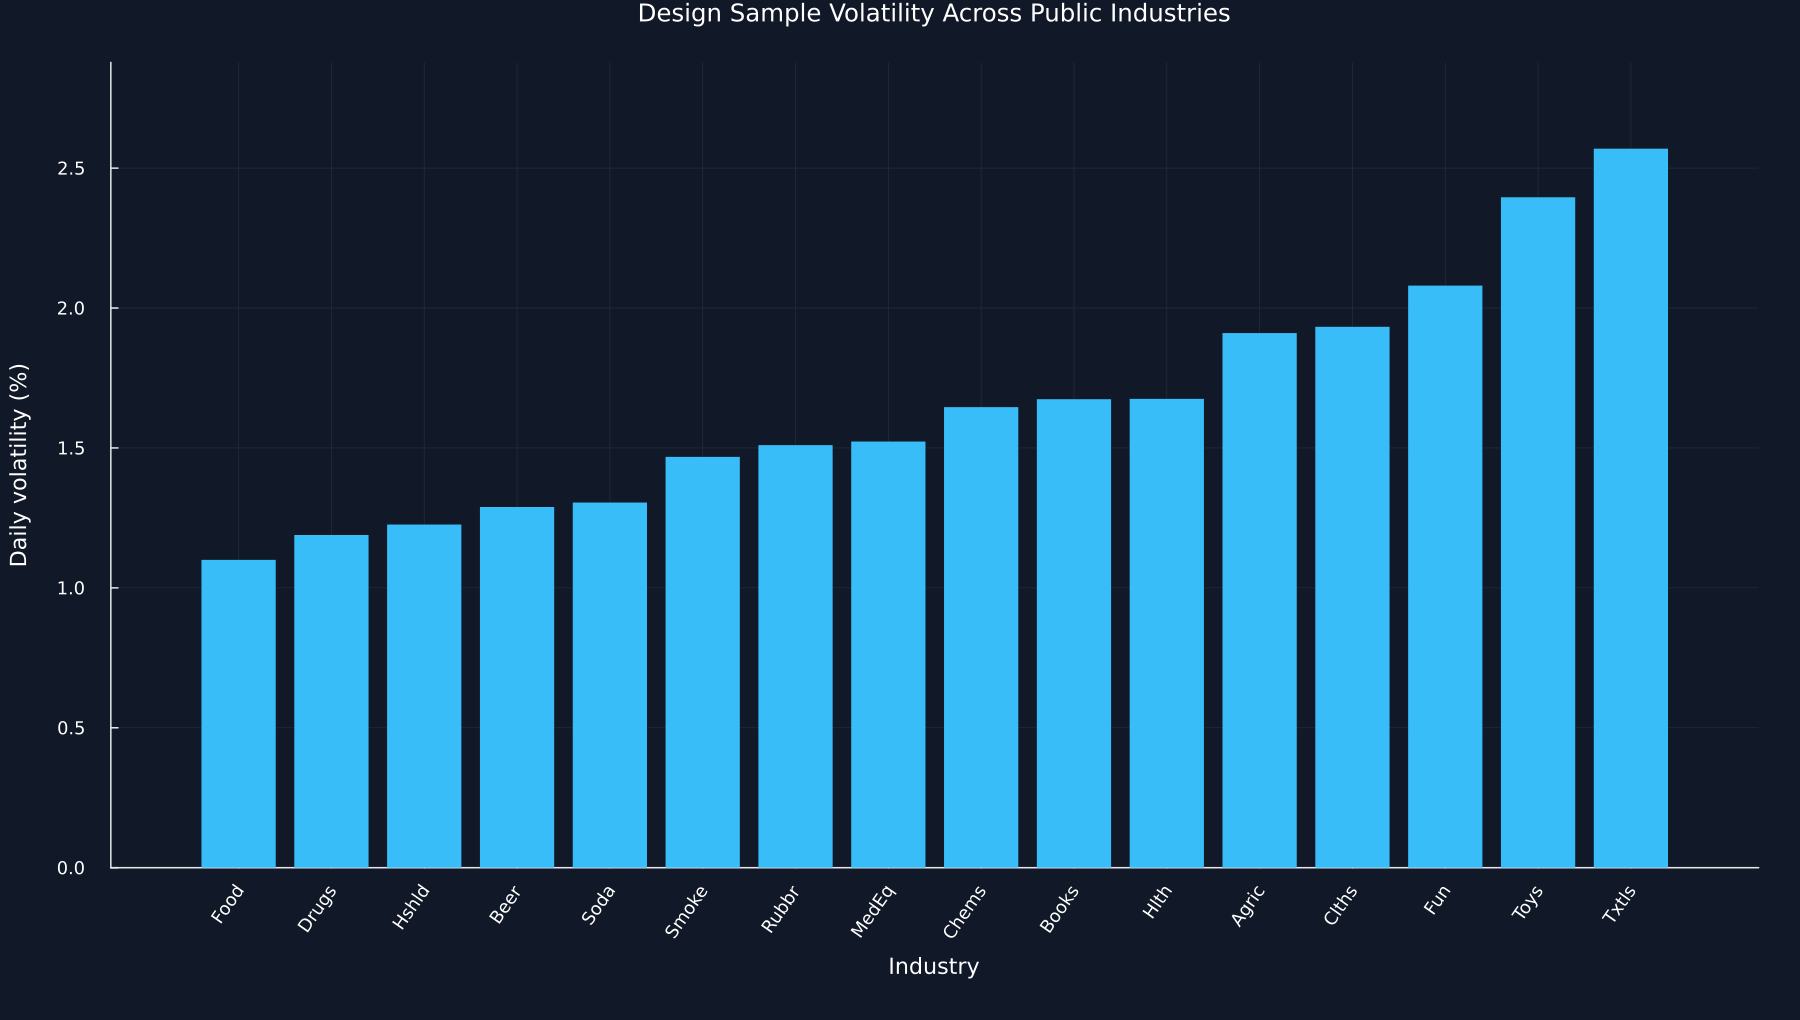

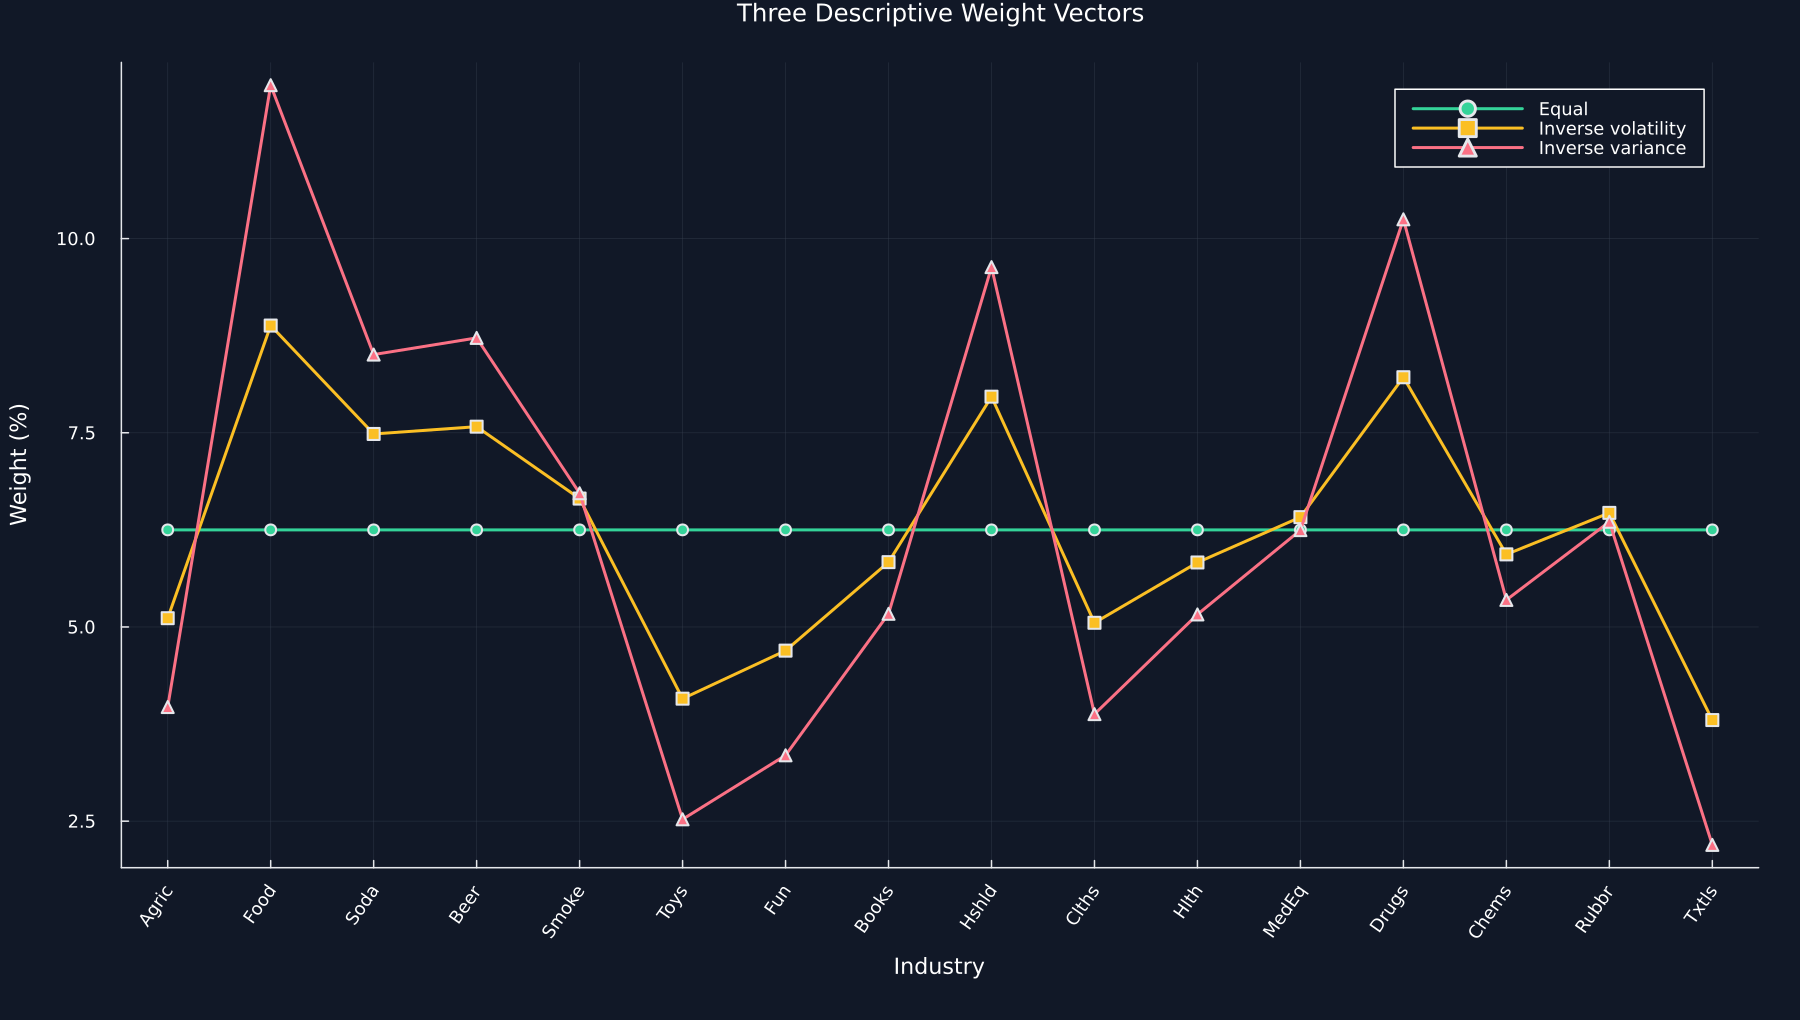

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("24_portfolio_majorization");
using CSV, Printf
using RiskLabAI.Optimization: birkhoff_von_neumann_decomposition,is_doubly_stochastic,is_majorized,majorization_matrix
violet = "#C084FC"
ordered(values) = sort(Float64.(values);rev=true)
partial_sums(values) = cumsum(ordered(values))
table(frame,name,caption) = save_table(frame,paths,name;caption,label="tab:chapter25-"*replace(name,"_"=>"-"))
function concentration_record(name,values)
    positive = values[values.>0]
    squared = sum(abs2,values)
    entropy = -sum(positive.*log.(positive))
    return (Vector=name,largest=maximum(values),squared=squared,fourth=sum(values.^4),effective=1/squared,entropy_effective=exp(entropy))
end
function concentration_table(vectors)
    frame = DataFrame([concentration_record(name,values) for (name,values) in vectors])
    rename!(frame,["Vector","Largest component","Squared sum","Fourth power sum","Effective count","Entropy effective count"])
    return frame
end
function matrix_table(matrix)
    return hcat(DataFrame("Matrix row"=>["Row "*string(i) for i in axes(matrix,1)]),DataFrame(matrix,["Column "*string(i) for i in axes(matrix,2)]))
end
function matrix_data(matrix)
    return hcat(DataFrame(row=collect(axes(matrix,1))),DataFrame(matrix,["x"*string(i) for i in axes(matrix,2)]))
end
function decomposition_data(weights,orders)
    return hcat(DataFrame(term=collect(eachindex(weights)),weight=weights),DataFrame(orders,["column_"*string(i) for i in axes(orders,2)]))
end
function restore_decomposition(weights,orders)
    identity = Matrix{Float64}(I,size(orders,2),size(orders,2))
    return sum(weight.*identity[orders[index,:],:] for (index,weight) in enumerate(weights))
end
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
public_lines = readlines(data_path)
title_index = findfirst(line->occursin("Average Value Weighted Returns -- Daily",line),public_lines)
header_index = title_index+1
end_index = findnext(line->isempty(strip(line)),public_lines,header_index+1)
raw = CSV.read(IOBuffer(join(public_lines[header_index:end_index-1],"\n")),DataFrame)
rename!(raw,names(raw)[1]=>"Date")
all_dates = Date.(string.(raw.Date),dateformat"yyyymmdd")
industries = names(raw)[2:17]
all_returns = Matrix{Float64}(raw[:,2:17])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all(all_returns.>-99;dims=2))
dates,returns = all_dates[valid],all_returns[valid,:]
design_indices,later_indices = findall(<=(Date(2023,12,31)),dates),findall(>=(Date(2024,1,1)),dates)
design,later = returns[design_indices,:],returns[later_indices,:]
@assert length(industries)==16
@assert length(dates)==1760
@assert length(design_indices)==1258
@assert length(later_indices)==502
@assert all(isfinite,returns)
provenance = DataFrame("Item"=>["Public source","Stored archive","Return type","Industries retained","Download during execution","Simulated observations"],"Value"=>["Kenneth R. French Data Library, 49 Industry Portfolios Daily","49_Industry_Portfolios_daily_CSV.zip","Value-weighted daily percentage returns","16","None","None"])
table(provenance,"public_data_provenance","Public data provenance for the Chapter 25 concentration study.")
periods = DataFrame("Sample"=>["Design","Later observations","Complete fixed window"],"First date"=>[first(dates[design_indices]),first(dates[later_indices]),first(dates)],"Last date"=>[last(dates[design_indices]),last(dates[later_indices]),last(dates)],"Daily observations"=>[length(design_indices),length(later_indices),length(dates)],"Use"=>["Estimate descriptive weights","Count and provenance only","Public data boundary"])
table(periods,"public_sample_periods","Chronological boundaries of the public data study.")
standard_deviation,variance = vec(std(design;dims=1)),vec(var(design;dims=1))
equal = fill(1/length(industries),length(industries))
inverse_volatility = (1 ./standard_deviation)./sum(1 ./standard_deviation)
inverse_variance = (1 ./variance)./sum(1 ./variance)
industry_summary = DataFrame("Industry"=>industries,"Mean daily return (%)"=>vec(mean(design;dims=1)),"Daily volatility (%)"=>standard_deviation,"Smallest daily return (%)"=>vec(minimum(design;dims=1)),"Largest daily return (%)"=>vec(maximum(design;dims=1)))
table(industry_summary,"industry_design_summary","Design sample summaries for the sixteen public industries.")
save_data(industry_summary,paths,"industry_volatility")
weights = DataFrame("Industry"=>industries,"Equal weight (%)"=>100 .*equal,"Inverse volatility weight (%)"=>100 .*inverse_volatility,"Inverse variance weight (%)"=>100 .*inverse_variance)
table(weights,"public_portfolio_weights","Descriptive portfolio weights estimated with data through 2023.")
save_data(weights,paths,"portfolio_weights")
save_data(hcat(DataFrame(date=dates),DataFrame(returns,industries)),paths,"public_industry_observations")
ranked = sortperm(standard_deviation)
figure = bar(1:16,standard_deviation[ranked];color=palette.cyan,linealpha=0,xticks=(1:16,industries[ranked]),xrotation=55,title="Design Sample Volatility Across Public Industries",xlabel="Industry",ylabel="Daily volatility (%)",ylims=(0,1.12*maximum(standard_deviation)),legend=false,size=(1200,680),bottom_margin=12Plots.mm)
save_figure(figure,paths,"industry_volatility")
figure = plot(;xticks=(1:16,industries),xrotation=55,title="Three Descriptive Weight Vectors",xlabel="Industry",ylabel="Weight (%)",legend=:topright,size=(1200,680),bottom_margin=12Plots.mm)
for (name,values,color,marker) in [("Equal",equal,palette.green,:circle),("Inverse volatility",inverse_volatility,palette.amber,:square),("Inverse variance",inverse_variance,palette.rose,:utriangle)]
    plot!(figure,1:16,100 .*values;color,marker,markersize=4,label=name)
end
save_figure(figure,paths,"portfolio_weights")


## Concentration Order in the Public Example

The ordered cumulative share of the largest $k$ weights is

$$
S_k(w)=\sum_{i=1}^{k}w_{[i]},
\qquad k=1,\ldots,n.
$$

Here, $w_{[i]}$ is the weight ranked $i$ after sorting and $S_k(w)$ is the share assigned to the $k$ largest positions. Comparing the complete sequence of partial sums is stronger than comparing only the largest weight or the squared concentration.

Row,Vector,Largest component,Squared sum,Fourth power sum,Effective count,Entropy effective count
,String,Float64,Float64,Float64,Float64,Float64
1,Equal,0.0625,0.0625,0.000244141,16.0,16.0
2,Inverse volatility,0.0888046,0.0658556,0.000325007,15.1847,15.5703
3,Inverse variance,0.119751,0.0749389,0.000593284,13.3442,14.4758


Row,Position,Equal,Inverse volatility,Inverse variance
,Int64,Float64,Float64,Float64
1,1,0.0625,0.0888046,0.119751
2,2,0.125,0.170957,0.222234
3,3,0.1875,0.250605,0.318562
4,4,0.25,0.326391,0.405776
5,5,0.3125,0.40124,0.490846
6,6,0.375,0.467773,0.558064
7,7,0.4375,0.532462,0.621606
8,8,0.5,0.596601,0.684073
9,9,0.5625,0.655946,0.737552


Row,Target,Source,Target majorized by source
,String,String,Bool
1,Equal,Inverse volatility,true
2,Equal,Inverse variance,true
3,Inverse volatility,Inverse variance,true


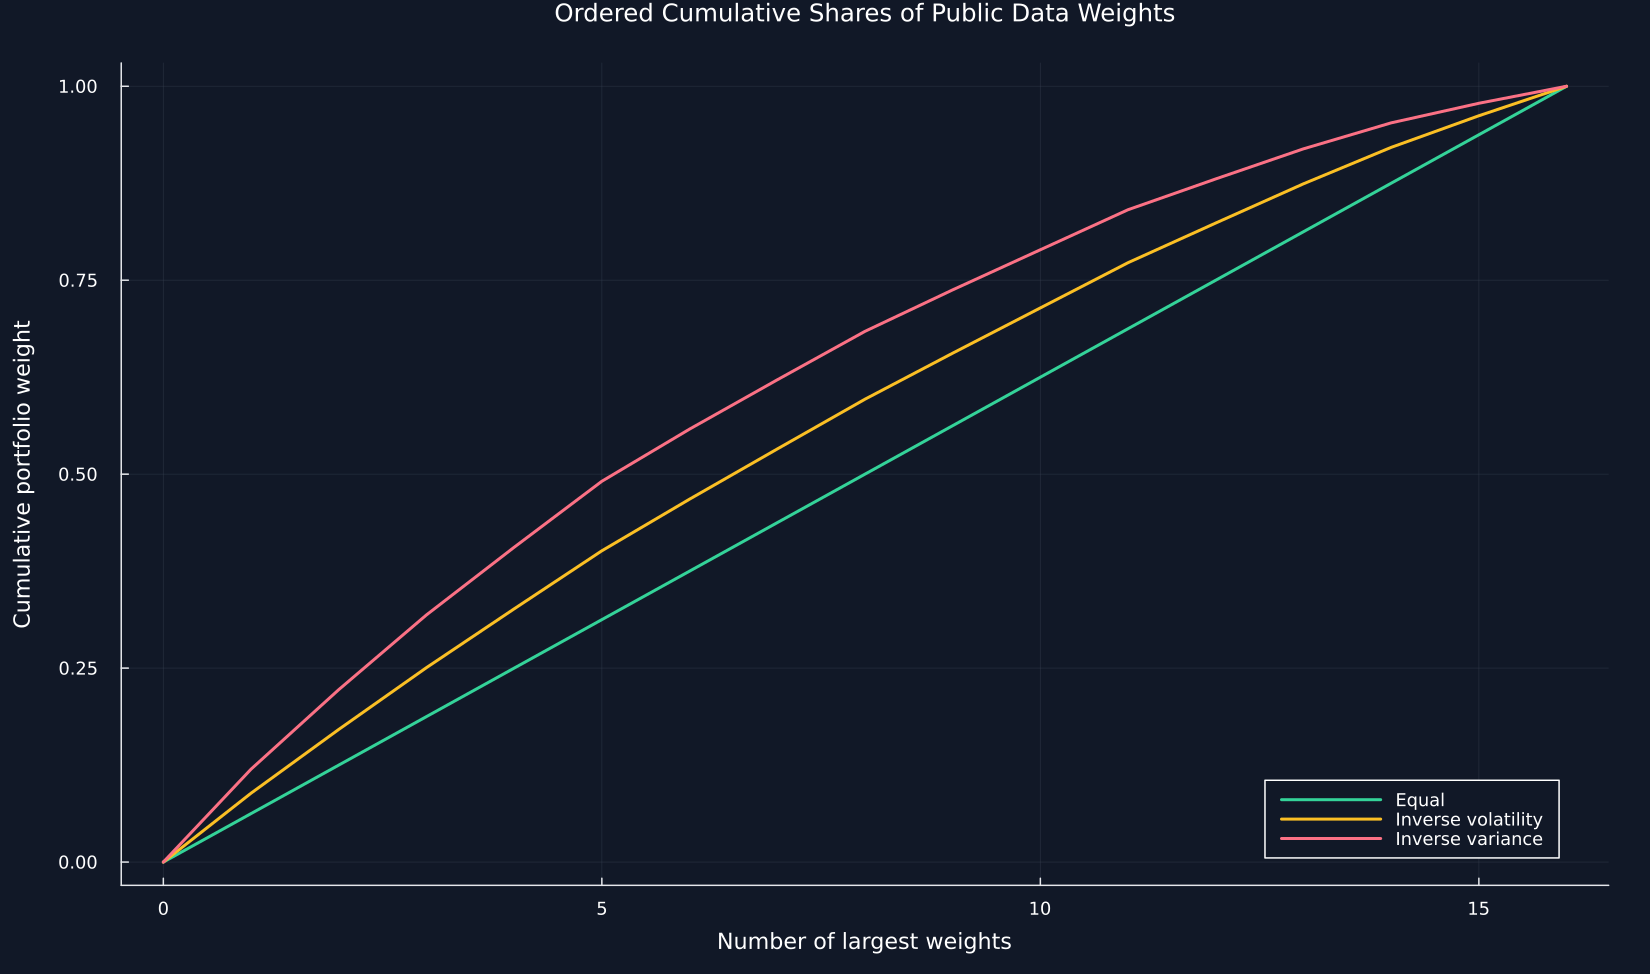

Row,Mixing fraction,Largest component,Squared sum,Fourth power sum,Effective count,Entropy effective count,Majorized by original
,Float64,Float64,Float64,Float64,Float64,Float64,Bool
1,0.0,0.119751,0.0749389,0.000593284,13.3442,14.4758,true
2,0.1,0.114026,0.0725755,0.000520734,13.7788,14.7627,true
3,0.2,0.108301,0.0704609,0.000458047,14.1923,15.0195,true
4,0.3,0.102576,0.068595,0.00040457,14.5783,15.2467,true
5,0.4,0.0968505,0.066978,0.000359705,14.9303,15.4444,true
6,0.5,0.0911254,0.0656097,0.0003229,15.2416,15.6125,true
7,0.6,0.0854003,0.0644902,0.000293659,15.5062,15.7508,true
8,0.7,0.0796752,0.0636195,0.000271533,15.7185,15.8591,true
9,0.8,0.0739502,0.0629976,0.000256127,15.8736,15.9371,true


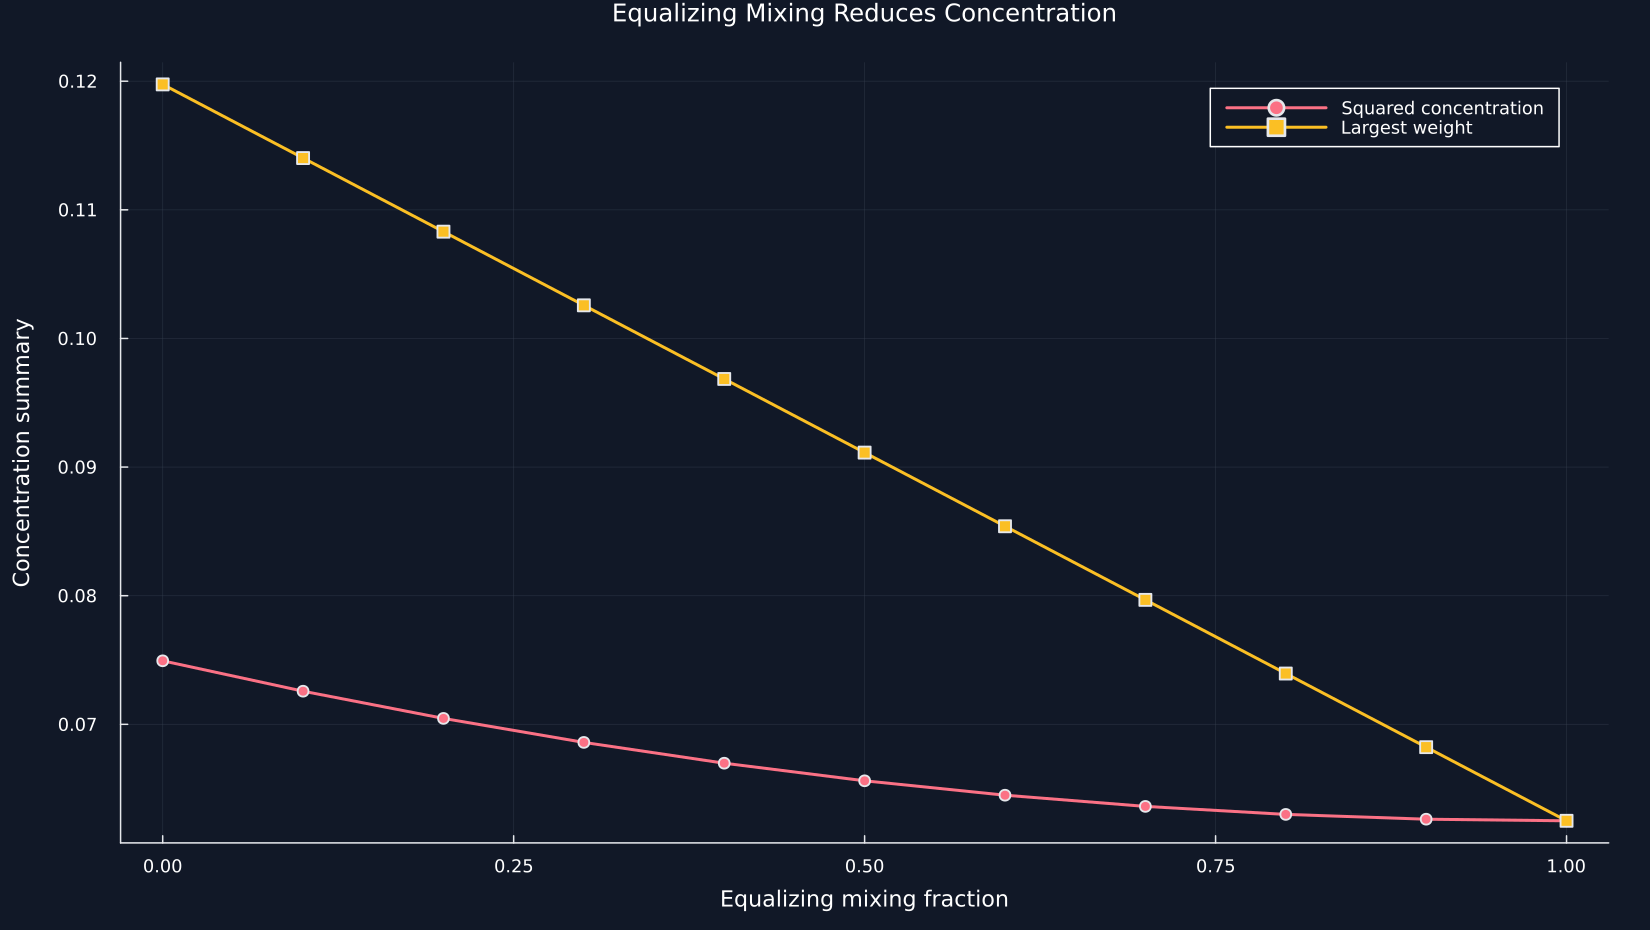

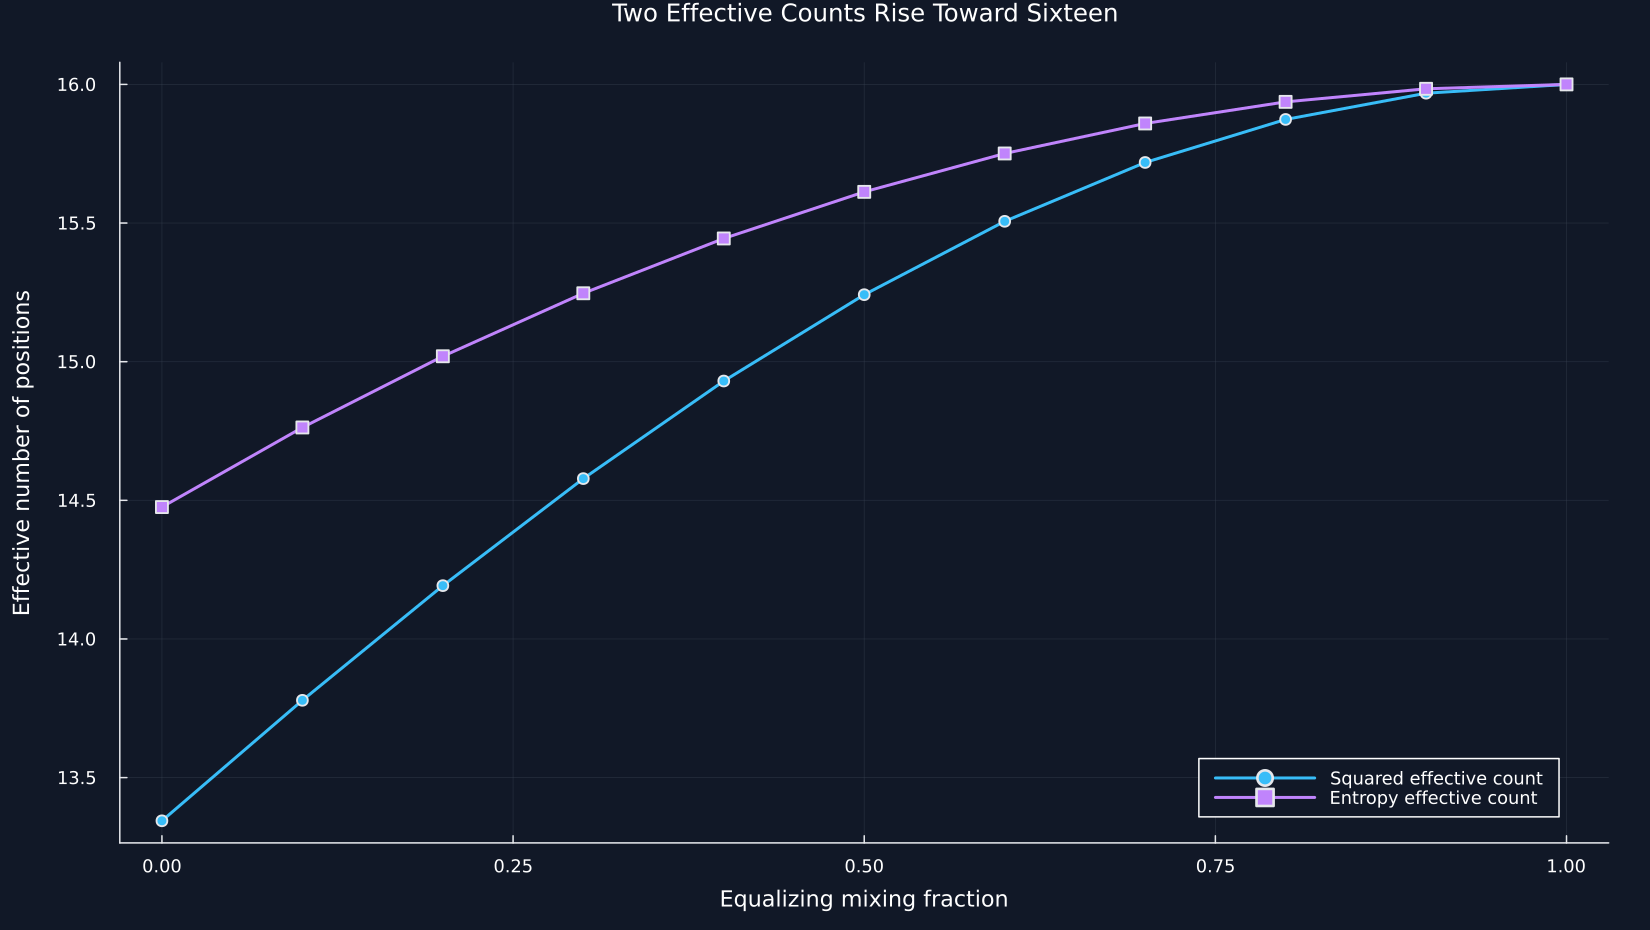

In [2]:
portfolio_vectors = ["Equal"=>equal,"Inverse volatility"=>inverse_volatility,"Inverse variance"=>inverse_variance]
public_concentration = concentration_table(portfolio_vectors)
table(public_concentration,"public_concentration_statistics","Concentration summaries for the three descriptive public data portfolios.")
public_partial = DataFrame("Position"=>1:16)
for (name,values) in portfolio_vectors
    public_partial[!,name] = partial_sums(values)
end
table(public_partial,"public_weight_partial_sums","Ordered cumulative shares of the three weight vectors.")
save_data(public_partial,paths,"public_weight_partial_sums")
relations = DataFrame("Target"=>["Equal","Equal","Inverse volatility"],"Source"=>["Inverse volatility","Inverse variance","Inverse variance"],"Target majorized by source"=>[is_majorized(equal,inverse_volatility),is_majorized(equal,inverse_variance),is_majorized(inverse_volatility,inverse_variance)])
table(relations,"public_majorization_relations","Majorization relations among the public data weight vectors.")
figure = plot(;title="Ordered Cumulative Shares of Public Data Weights",xlabel="Number of largest weights",ylabel="Cumulative portfolio weight",legend=:bottomright,size=(1100,650))
for ((name,values),color) in zip(portfolio_vectors,[palette.green,palette.amber,palette.rose])
    plot!(figure,0:16,vcat(0.0,partial_sums(values));color,label=name)
end
save_figure(figure,paths,"public_weight_partial_sums")
alphas = collect(range(0.0,1.0;length=11))
identity = Matrix{Float64}(I,16,16)
equalizer = fill(1/16,16,16)
mixed_values = reduce(vcat,[transpose(((1-alpha)*identity+alpha*equalizer)*inverse_variance) for alpha in alphas])
mixed_vectors = [@sprintf("alpha=%.1f",alpha)=>vec(mixed_values[index,:]) for (index,alpha) in enumerate(alphas)]
mixing_path = concentration_table(mixed_vectors)
select!(mixing_path,Not(:Vector))
insertcols!(mixing_path,1,"Mixing fraction"=>alphas)
mixing_path[!,"Majorized by original"] = [is_majorized(collect(row),inverse_variance) for row in eachrow(mixed_values)]
table(mixing_path,"public_mixing_path","Concentration along the equalizing doubly stochastic path.")
save_data(mixing_path,paths,"mixing_concentration_path")
save_data(matrix_data(mixed_values),paths,"public_mixed_weights")
figure = plot(alphas,mixing_path[!,"Squared sum"];marker=:circle,color=palette.rose,label="Squared concentration",xlabel="Equalizing mixing fraction",ylabel="Concentration summary",title="Equalizing Mixing Reduces Concentration",legend=:topright,size=(1100,620))
plot!(figure,alphas,mixing_path[!,"Largest component"];marker=:square,color=palette.amber,label="Largest weight")
save_figure(figure,paths,"mixing_concentration_path")
figure = plot(alphas,mixing_path[!,"Effective count"];marker=:circle,color=palette.cyan,label="Squared effective count",xlabel="Equalizing mixing fraction",ylabel="Effective number of positions",title="Two Effective Counts Rise Toward Sixteen",legend=:bottomright,size=(1100,620))
plot!(figure,alphas,mixing_path[!,"Entropy effective count"];marker=:square,color=violet,label="Entropy effective count")
save_figure(figure,paths,"mixing_effective_count_path")


## What the Concentration Study Establishes

At mixing fraction $a\in[0,1]$, the equalizing matrix is

$$
D(a)=(1-a)I+a\frac{\mathbf{1}\mathbf{1}^{\mathsf T}}{n}.
$$

Here, $I$ is the identity matrix, $\mathbf{1}$ is the vector of ones, $n=16$, and $a$ controls the amount of mixing. The matrix is doubly stochastic for every stated $a$. Applying it to the inverse variance vector traces a checked path toward equal weight. This exercise establishes concentration order and numerical reconstruction only. It does not compare later returns, estimate transaction costs, or recommend a portfolio.

Row,Target,Source,Doubly stochastic,Largest mapping residual,Largest row sum residual,Largest column sum residual
,String,String,Bool,Float64,Float64,Float64
1,Inverse volatility,Inverse variance,true,3.43059e-14,3.19966e-13,3.80362e-13
2,Equal,Inverse variance,true,4.09395e-16,2.30926e-13,2.38698e-14


Row,Quantity,Value
,String,Float64
1,Returned permutation terms,20.0
2,Weight sum,1.0
3,Smallest positive weight,0.03125
4,Largest reconstruction residual,0.0


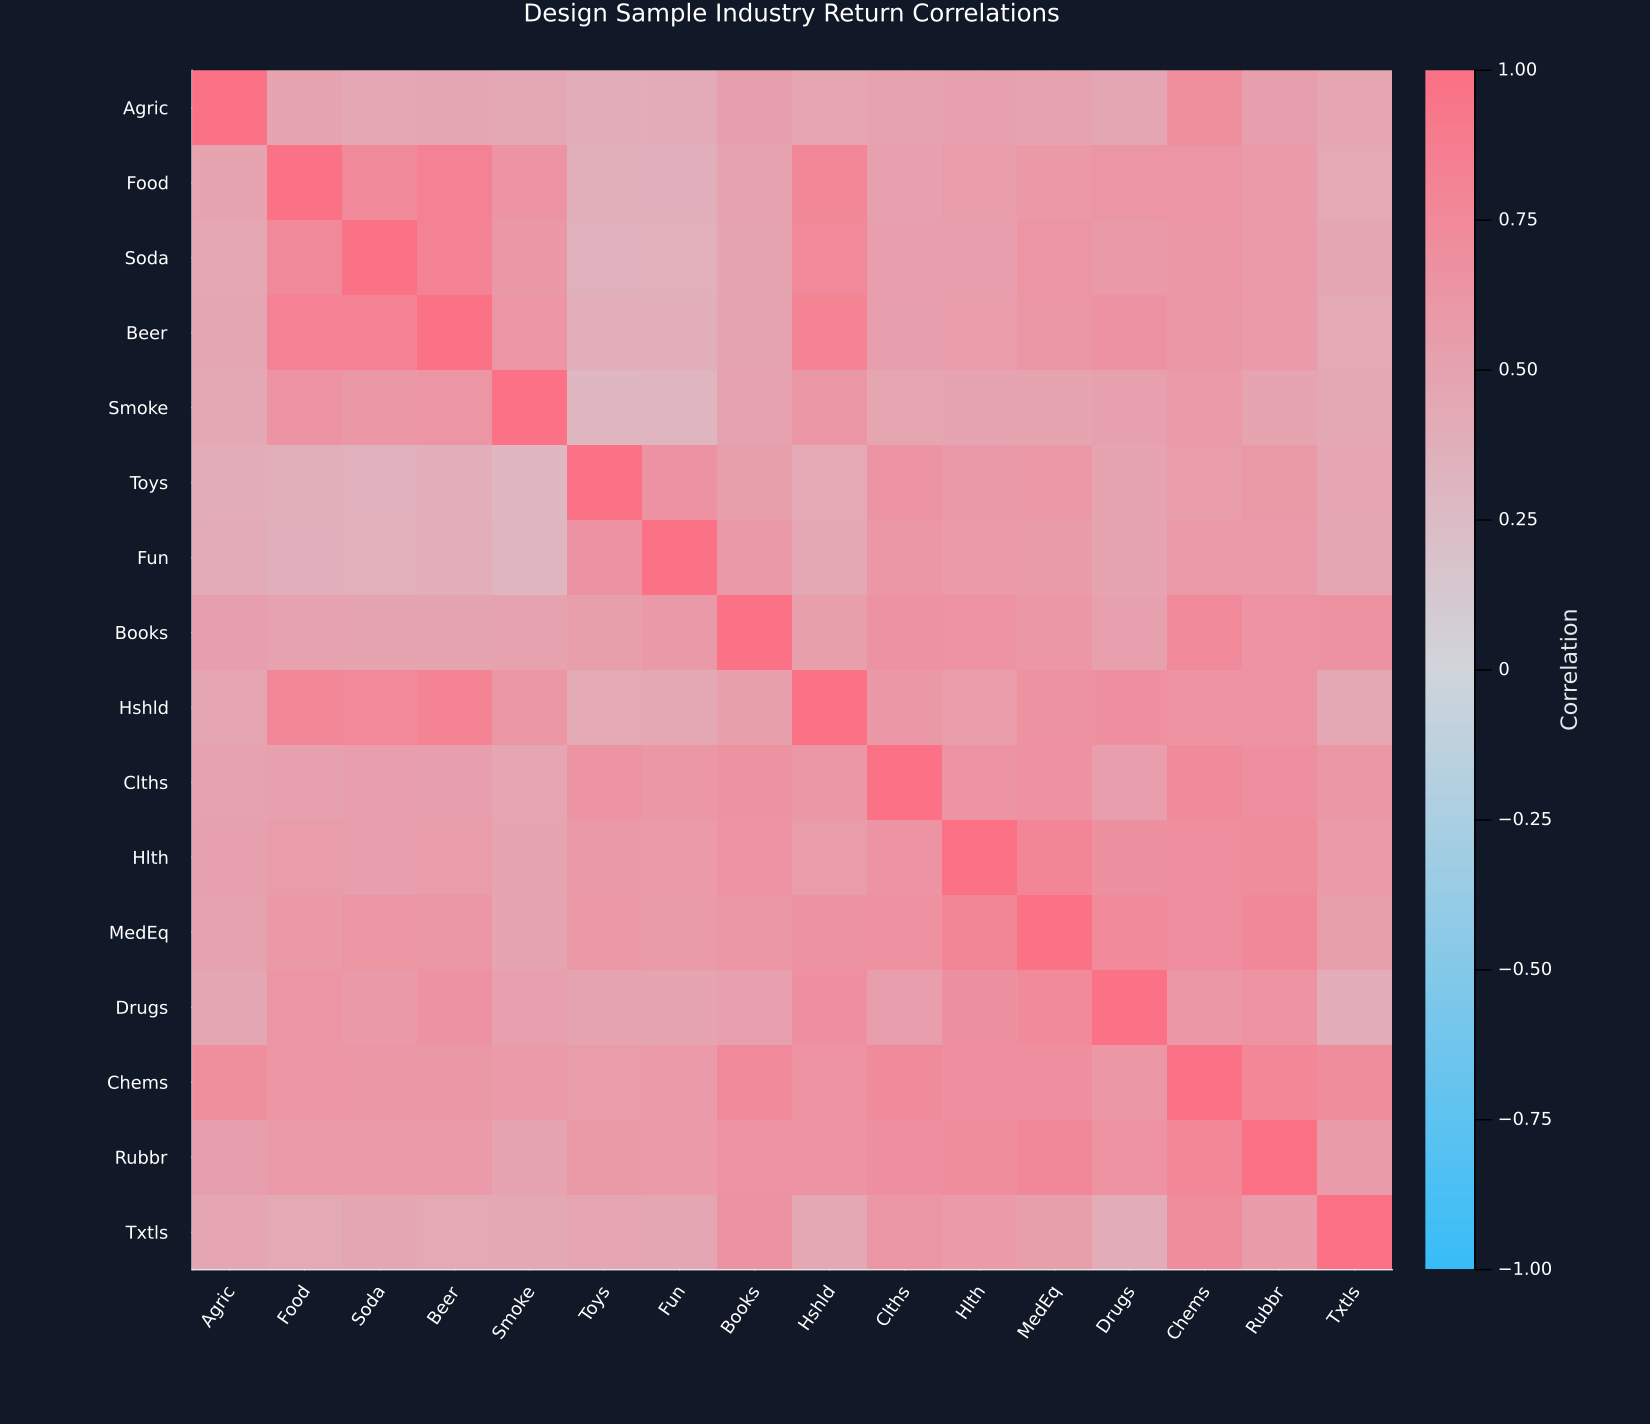

Row,Question,Answered,Boundary
,String,Bool,String
1,Are the vectors ordered by majorization?,true,Within the fixed design with sixteen industries
2,Do the witnesses reconstruct the targets?,true,Within absolute numerical tolerance
3,Which vector has the best later return?,false,No performance comparison is made
4,Are costs and turnover estimated?,false,No trading model is used
5,Is any portfolio recommended?,false,The study is descriptive


In [3]:
source_public = inverse_variance
witness_rows = NamedTuple[]
for (target_name,target_public) in [("Inverse volatility",inverse_volatility),("Equal",equal)]
    public_witness = majorization_matrix(target_public,source_public)
    push!(witness_rows,(Target=target_name,Source="Inverse variance",stochastic=is_doubly_stochastic(public_witness),mapping=maximum(abs,public_witness*source_public-target_public),rows=maximum(abs,vec(sum(public_witness;dims=2)).-1),columns=maximum(abs,vec(sum(public_witness;dims=1)).-1)))
    save_data(matrix_data(public_witness),paths,"public_witness_"*replace(lowercase(target_name)," "=>"_"))
end
witness_checks = DataFrame(witness_rows)
rename!(witness_checks,["Target","Source","Doubly stochastic","Largest mapping residual","Largest row sum residual","Largest column sum residual"])
table(witness_checks,"public_witness_checks","Checked stochastic witnesses for the public data weight vectors.")
half_matrix = 0.5identity+0.5equalizer
decomposition_weights,decomposition_orders = birkhoff_von_neumann_decomposition(half_matrix)
half_restored = restore_decomposition(decomposition_weights,decomposition_orders)
decomposition_check = DataFrame("Quantity"=>["Returned permutation terms","Weight sum","Smallest positive weight","Largest reconstruction residual"],"Value"=>[length(decomposition_weights),sum(decomposition_weights),minimum(decomposition_weights),maximum(abs,half_restored-half_matrix)])
table(decomposition_check,"public_equalizer_decomposition","Birkhoff reconstruction of the halfway equalizing matrix.")
save_data(decomposition_data(decomposition_weights,decomposition_orders),paths,"public_equalizer_terms")
save_data(matrix_data(half_restored),paths,"public_equalizer_restored")
correlation = cor(design)
save_data(hcat(DataFrame(Industry=industries),DataFrame(correlation,industries)),paths,"design_correlation_heatmap")
figure = heatmap(1:16,1:16,correlation;color=cgrad([palette.cyan,"#D1D5DB",palette.rose]),clims=(-1,1),yflip=true,aspect_ratio=:equal,xticks=(1:16,industries),yticks=(1:16,industries),xrotation=55,xlims=(0.5,16.5),ylims=(0.5,16.5),widen=false,title="Design Sample Industry Return Correlations",colorbar_title="Correlation",size=(1100,950),left_margin=12Plots.mm,bottom_margin=12Plots.mm)
save_figure(figure,paths,"design_correlation_heatmap")
limits = DataFrame("Question"=>["Are the vectors ordered by majorization?","Do the witnesses reconstruct the targets?","Which vector has the best later return?","Are costs and turnover estimated?","Is any portfolio recommended?"],"Answered"=>[true,true,false,false,false],"Boundary"=>["Within the fixed design with sixteen industries","Within absolute numerical tolerance","No performance comparison is made","No trading model is used","The study is descriptive"])
table(limits,"public_study_boundaries","Questions answered and not answered by the public data study.")
@assert all(relations[!,"Target majorized by source"])
@assert all(witness_checks[!,"Doubly stochastic"])
@assert maximum(witness_checks[!,"Largest mapping residual"])<=1e-10
@assert maximum(abs,half_restored-half_matrix)<=1e-10
@assert all(diff(mixing_path[!,"Squared sum"]).<=1e-12)
@assert all(diff(mixing_path[!,"Effective count"]).>=-1e-12)
@assert all(decomposition_weights.>0)
@assert abs(sum(decomposition_weights)-1)<=1e-10
@assert all(sort(collect(row))==collect(1:16) for row in eachrow(decomposition_orders))
@assert isfile(joinpath(paths.figures,"industry_volatility.pdf"))
@assert isfile(joinpath(paths.figures,"portfolio_weights.pdf"))
@assert isfile(joinpath(paths.figures,"public_weight_partial_sums.pdf"))
@assert isfile(joinpath(paths.figures,"mixing_concentration_path.pdf"))
@assert isfile(joinpath(paths.figures,"mixing_effective_count_path.pdf"))
@assert isfile(joinpath(paths.figures,"design_correlation_heatmap.pdf"))
